# 06 — Integrationsregeln und Anwendungen

**Voraussetzungen:** [05_Integralrechnung_Einfuehrung](05_Integralrechnung_Einfuehrung.ipynb), [03_Ableitungsregeln](03_Ableitungsregeln.ipynb)

---

## Lernziele

Nach diesem Notebook kannst du:
- **Substitution** anwenden, um verkettete Funktionen zu integrieren
- **Partielle Integration** für Produkte einsetzen
- **Flächen zwischen zwei Kurven** berechnen
- Typische Integrale der Matura sicher lösen

### 1. Integration durch Substitution

Die Substitution ist das Gegenstück zur **Kettenregel** beim Ableiten.

> **Idee:** Ersetze einen komplizierten Ausdruck durch eine neue Variable $u$, integriere einfacher, und setze zurück.

**Formel:**

$$\int f(g(x)) \cdot g'(x)\, dx = \int f(u)\, du \quad \text{mit } u = g(x)$$

**Schritt-für-Schritt:**
1. Wähle $u = g(x)$ (der „innere Teil")
2. Berechne $\frac{du}{dx} = g'(x)$ und forme um zu $du = g'(x)\, dx$
3. Ersetze im Integral: $\int f(g(x)) \cdot g'(x)\, dx = \int f(u)\, du$
4. Integriere nach $u$
5. Rücksubstitution: Setze $u = g(x)$ wieder ein

---

**Beispiel 1:** $\displaystyle\int 2x \cdot e^{x^2}\, dx$

1. Setze $u = x^2$
2. $\frac{du}{dx} = 2x \Rightarrow du = 2x\, dx$
3. Das Integral wird: $\int e^u\, du$
4. Integrieren: $e^u + C$
5. Rücksubstitution: $e^{x^2} + C$ ✓

**Beispiel 2:** $\displaystyle\int \cos(3x)\, dx$

1. Setze $u = 3x$
2. $\frac{du}{dx} = 3 \Rightarrow dx = \frac{du}{3}$
3. Das Integral wird: $\int \cos(u) \cdot \frac{1}{3}\, du = \frac{1}{3}\int \cos(u)\, du$
4. Integrieren: $\frac{1}{3}\sin(u) + C$
5. Rücksubstitution: $\frac{1}{3}\sin(3x) + C$ ✓

---

### Substitution bei bestimmten Integralen

Bei bestimmten Integralen **müssen auch die Grenzen angepasst** werden!

**Beispiel:** $\displaystyle\int_0^2 x(x^2+1)^3\, dx$

1. Setze $u = x^2 + 1$
2. $du = 2x\, dx \Rightarrow x\, dx = \frac{du}{2}$
3. **Grenzen anpassen:**
   - $x = 0 \Rightarrow u = 0^2 + 1 = 1$
   - $x = 2 \Rightarrow u = 2^2 + 1 = 5$
4. Integral: $\displaystyle\int_1^5 u^3 \cdot \frac{1}{2}\, du = \frac{1}{2}\left[\frac{u^4}{4}\right]_1^5 = \frac{1}{8}(625 - 1) = 78$

In [2]:
import sympy as sp

x = sp.Symbol('x')

print("=== Substitution mit SymPy verifizieren ===")
print()

# Beispiel 1: ∫ 2x·e^(x²) dx
integral_1 = sp.integrate(2*x * sp.exp(x**2), x)
print(f"∫ 2x·e^(x²) dx  = {integral_1}  + C")

# Beispiel 2: ∫ cos(3x) dx
integral_2 = sp.integrate(sp.cos(3*x), x)
print(f"∫ cos(3x) dx    = {integral_2}  + C")

# Weitere Beispiele
print(f"∫ (2x+1)⁵ dx   = {sp.integrate((2*x+1)**5, x)}  + C")
print(f"∫ x·√(x²+1) dx = {sp.integrate(x*sp.sqrt(x**2+1), x)}  + C")
print(f"∫ 1/(x·ln(x)) dx = {sp.integrate(1/(x*sp.ln(x)), x)}  + C")

# Bestimmtes Integral mit Grenzenwechsel
print("\n=== Bestimmtes Integral mit Substitution ===")
integral_best = sp.integrate(x*(x**2+1)**3, (x, 0, 2))
print(f"∫₀² x(x²+1)³ dx = {integral_best} = {float(integral_best)}")

# Probe: Ableitung der Stammfunktion
print("\n=== Probe (Ableitung der Stammfunktion) ===")
F = sp.exp(x**2)
print(f"d/dx [e^(x²)] = {sp.diff(F, x)}  ✓")

=== Substitution mit SymPy verifizieren ===

∫ 2x·e^(x²) dx  = exp(x**2)  + C
∫ cos(3x) dx    = sin(3*x)/3  + C
∫ (2x+1)⁵ dx   = 16*x**6/3 + 16*x**5 + 20*x**4 + 40*x**3/3 + 5*x**2 + x  + C
∫ x·√(x²+1) dx = x**2*sqrt(x**2 + 1)/3 + sqrt(x**2 + 1)/3  + C
∫ 1/(x·ln(x)) dx = log(log(x))  + C

=== Bestimmtes Integral mit Substitution ===
∫₀² x(x²+1)³ dx = 78 = 78.0

=== Probe (Ableitung der Stammfunktion) ===
d/dx [e^(x²)] = 2*x*exp(x**2)  ✓


### 2. Partielle Integration

Die partielle Integration ist das Gegenstück zur **Produktregel** beim Ableiten.

> **Formel:**
> $$\int u(x) \cdot v'(x)\, dx = u(x) \cdot v(x) - \int u'(x) \cdot v(x)\, dx$$

Kurz: $\int u\, dv = uv - \int v\, du$

**Wann anwenden?** Diese Regel ist angebracht, wenn ein Produkt zweier Funktionen unterschiedlichen Typs integriert werden soll, und weder Substitution noch andere Vereinfachungen möglich sind.

**Strategie — LIATE-Regel** (wähle $u$ nach dieser Priorität):

| Priorität | Typ | Beispiel |
|-----------|-----|----------|
| 1 | **L**ogarithmus | $\ln x$ |
| 2 | **I**nverse Trig | $\arctan x$ |
| 3 | **A**lgebraisch | $x^2, x, 3x+1$ |
| 4 | **T**rigonometrisch | $\sin x, \cos x$ |
| 5 | **E**xponentiell | $e^x$ |

---

**Beispiel:** $\displaystyle\int x \cdot e^x\, dx$

| Wahl | |
|------|---|
| $u = x$ | $u' = 1$ |
| $v' = e^x$ | $v = e^x$ |

$$\int x \cdot e^x\, dx = x \cdot e^x - \int 1 \cdot e^x\, dx = x e^x - e^x + C = e^x(x-1) + C$$

---

**Beispiel:** $\displaystyle\int \ln x\, dx$

| Wahl | |
|------|---|
| $u = \ln x$ | $u' = \frac{1}{x}$ |
| $v' = 1$ | $v = x$ |

$$\int \ln x\, dx = x \ln x - \int x \cdot \frac{1}{x}\, dx = x \ln x - x + C$$

In [3]:
import sympy as sp

x = sp.Symbol('x')

print("=== Partielle Integration mit SymPy ===")
print()
print(f"∫ x·eˣ dx   = {sp.integrate(x*sp.exp(x), x)}  + C")
print(f"∫ ln(x) dx  = {sp.integrate(sp.ln(x), x)}  + C")
print(f"∫ x·sin(x) dx = {sp.integrate(x*sp.sin(x), x)}  + C")
print(f"∫ x²·eˣ dx  = {sp.integrate(x**2*sp.exp(x), x)}  + C  (2x partielle Int.)")

# Probe
print("\n=== Probe ===")
F = sp.exp(x)*(x-1)
print(f"d/dx [eˣ(x-1)] = {sp.diff(F, x).simplify()}  ✓")

=== Partielle Integration mit SymPy ===

∫ x·eˣ dx   = (x - 1)*exp(x)  + C
∫ ln(x) dx  = x*log(x) - x  + C
∫ x·sin(x) dx = -x*cos(x) + sin(x)  + C
∫ x²·eˣ dx  = (x**2 - 2*x + 2)*exp(x)  + C  (2x partielle Int.)

=== Probe ===
d/dx [eˣ(x-1)] = x*exp(x)  ✓


### 3. Überblick: Welche Methode wann?

| Integraltyp | Methode | Beispiel |
|-------------|---------|----------|
| Grundintegral | Tabelle | $\int x^3\, dx$ |
| Lineares Argument | Schnelle Substitution | $\int e^{2x}\, dx = \frac{1}{2}e^{2x}$ |
| Verkettung mit $g'(x)$ sichtbar | Substitution | $\int 2x \cdot e^{x^2}\, dx$ |
| Produkt (verschiedene Typen) | Partielle Integration | $\int x \cdot e^x\, dx$ |
| Bruch mit Polynomen | Polynomdivision + Partialbrüche | $\int \frac{x^2}{x-1}\, dx$ |
| $\frac{0}{0}$-Form (Bruch, vereinfachbar) | Kürzen, dann integrieren | $\int \frac{x^2-1}{x-1}\, dx$ |

> *Hinweis:* In der Matura sind meist Substitution und partielle Integration die wichtigsten Techniken.

### 4. Fläche zwischen zwei Kurven

Die Fläche zwischen $f(x)$ (oben) und $g(x)$ (unten) auf $[a, b]$:

$$A = \int_a^b [f(x) - g(x)]\, dx$$

**Schritt-für-Schritt:**
1. Schnittpunkte finden: $f(x) = g(x)$
2. Bestimme, welche Funktion oben/unten liegt
3. Integriere die Differenz

**Beispiel:** Fläche zwischen $f(x) = -x^2 + 4$ und $g(x) = x^2 - 2x$

Schnittpunkte: $-x^2 + 4 = x^2 - 2x \Rightarrow 2x^2 - 2x - 4 = 0 \Rightarrow x = -1$ oder $x = 2$

Schnittpunkte: x = [-1, 2]
Fläche = ∫₋₁² [f(x)-g(x)] dx = 9 = 9.0000


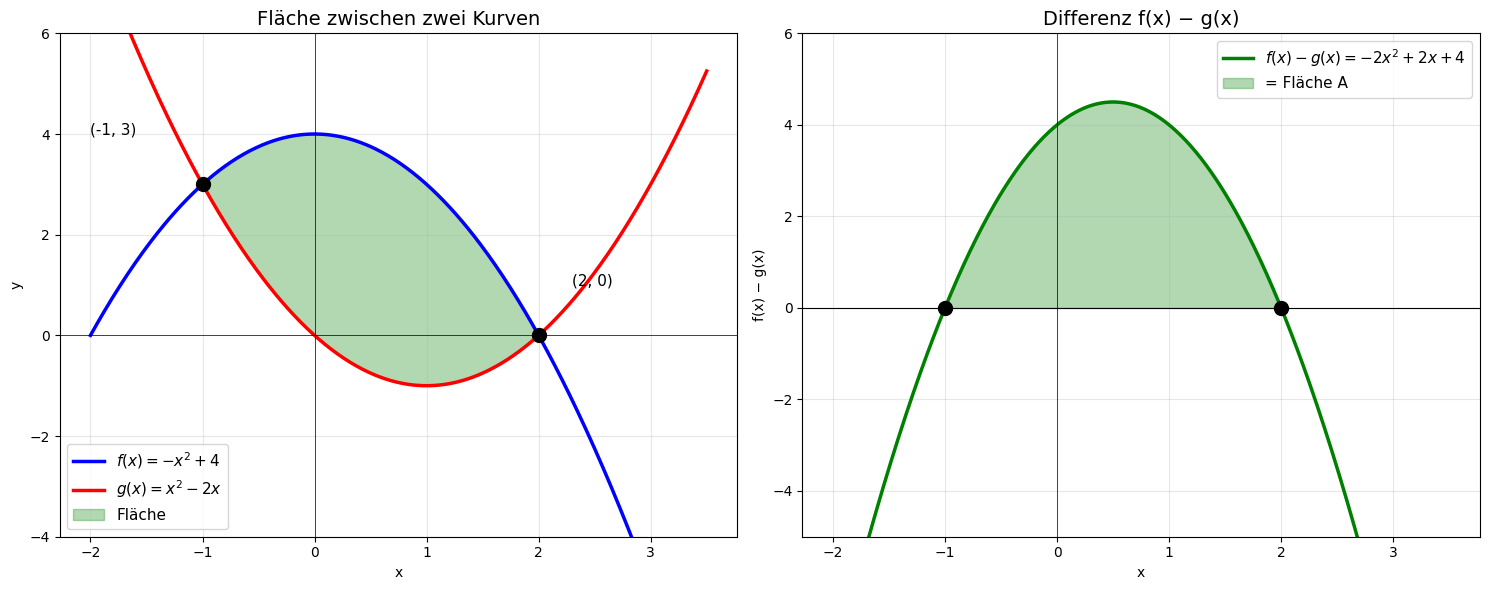

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# --- Fläche zwischen zwei Kurven ---

def visualisiere_flaeche_zwischen_kurven():
    """Berechnet und visualisiert die Fläche zwischen f(x) und g(x)."""
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    
    # Funktionen
    f = lambda x: -x**2 + 4
    g = lambda x: x**2 - 2*x
    x = np.linspace(-2, 3.5, 500)
    
    # Schnittpunkte
    a, b = -1, 2
    x_fill = np.linspace(a, b, 300)
    
    # --- Links: Beide Funktionen mit Fläche ---
    ax = axes[0]
    ax.plot(x, f(x), 'b-', linewidth=2.5, label=r"$f(x) = -x^2 + 4$")
    ax.plot(x, g(x), 'r-', linewidth=2.5, label=r"$g(x) = x^2 - 2x$")
    ax.fill_between(x_fill, f(x_fill), g(x_fill), alpha=0.3, color='green',
                    label="Fläche")
    ax.scatter([a, b], [f(a), f(b)], color='black', s=100, zorder=5)
    ax.annotate(f"({a}, {f(a)})", xy=(a, f(a)), xytext=(a-1, f(a)+1), fontsize=11)
    ax.annotate(f"({b}, {f(b)})", xy=(b, f(b)), xytext=(b+0.3, f(b)+1), fontsize=11)
    ax.set_title("Fläche zwischen zwei Kurven", fontsize=14)
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.axvline(0, color='black', linewidth=0.5)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_ylim(-4, 6)
    
    # --- Rechts: Differenzfunktion ---
    ax = axes[1]
    diff = f(x) - g(x)
    diff_fill = f(x_fill) - g(x_fill)
    ax.plot(x, diff, 'green', linewidth=2.5, label=r"$f(x) - g(x) = -2x^2 + 2x + 4$")
    ax.fill_between(x_fill, diff_fill, alpha=0.3, color='green', label="= Fläche A")
    ax.axhline(0, color='black', linewidth=0.8)
    ax.scatter([a, b], [0, 0], color='black', s=100, zorder=5)
    ax.set_title("Differenz f(x) − g(x)", fontsize=14)
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.axvline(0, color='black', linewidth=0.5)
    ax.set_xlabel("x")
    ax.set_ylabel("f(x) − g(x)")
    ax.set_ylim(-5, 6)
    
    plt.tight_layout()
    plt.show()

# --- SymPy Berechnung ---
x = sp.Symbol('x')
f_sym = -x**2 + 4
g_sym = x**2 - 2*x
differenz = f_sym - g_sym

# Schnittpunkte
schnittpunkte = sp.solve(sp.Eq(f_sym, g_sym), x)
print(f"Schnittpunkte: x = {schnittpunkte}")

# Fläche
flaeche = sp.integrate(differenz, (x, -1, 2))
print(f"Fläche = ∫₋₁² [f(x)-g(x)] dx = {flaeche} = {float(flaeche):.4f}")

visualisiere_flaeche_zwischen_kurven()

### 5. Anwendungen der Integralrechnung

| Anwendung | Formel |
|-----------|--------|
| **Fläche unter Kurve** | $A = \int_a^b f(x)\, dx$ |
| **Fläche zwischen Kurven** | $A = \int_a^b [f(x) - g(x)]\, dx$ |
| **Mittlerer Funktionswert** | $\bar{f} = \frac{1}{b-a} \int_a^b f(x)\, dx$ |
| **Weg aus Geschwindigkeit** | $s(t) = \int_0^t v(\tau)\, d\tau$ |
| **Gesamtmenge aus Rate** | $\text{Menge} = \int_0^T \text{Rate}(t)\, dt$ |

---

**Beispiel: Mittlerer Funktionswert**

Die Durchschnittstemperatur von $T(t) = 20 + 5\sin\left(\frac{\pi t}{12}\right)$ über 24 Stunden:

$$\bar{T} = \frac{1}{24}\int_0^{24} \left[20 + 5\sin\left(\frac{\pi t}{12}\right)\right] dt$$

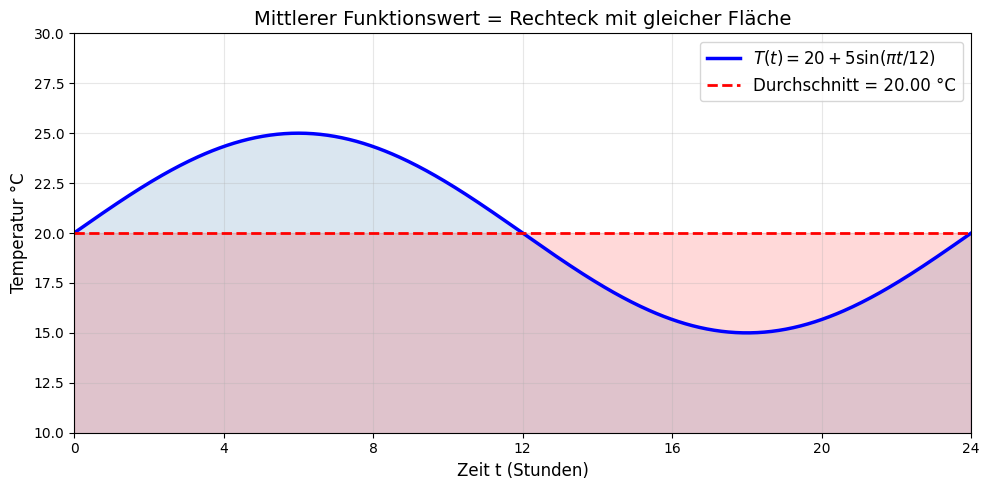

Integral: ∫₀²⁴ T(t) dt = 480.00
Mittlerer Wert: 480.00 / 24 = 20.00 °C


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# --- Mittlerer Funktionswert visualisieren ---

def visualisiere_mittelwert():
    """Zeigt den mittleren Funktionswert als Rechteckhöhe."""
    fig, ax = plt.subplots(figsize=(10, 5))
    
    t = np.linspace(0, 24, 500)
    T = 20 + 5*np.sin(np.pi*t/12)
    
    # Mittlerer Wert berechnen
    t_sym = sp.Symbol('t')
    T_sym = 20 + 5*sp.sin(sp.pi*t_sym/12)
    integral = sp.integrate(T_sym, (t_sym, 0, 24))
    mittelwert = float(integral / 24)
    
    # Temperaturkurve
    ax.plot(t, T, 'b-', linewidth=2.5, label=r"$T(t) = 20 + 5\sin(\pi t/12)$")
    ax.fill_between(t, T, alpha=0.2, color='steelblue')
    
    # Mittelwert-Linie
    ax.axhline(mittelwert, color='red', linestyle='--', linewidth=2,
               label=f"Durchschnitt = {mittelwert:.2f} °C")
    ax.fill_between(t, mittelwert, alpha=0.15, color='red')
    
    ax.set_xlabel("Zeit t (Stunden)", fontsize=12)
    ax.set_ylabel("Temperatur °C", fontsize=12)
    ax.set_title("Mittlerer Funktionswert = Rechteck mit gleicher Fläche", fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0, 24)
    ax.set_ylim(10, 30)
    ax.set_xticks(range(0, 25, 4))
    
    plt.tight_layout()
    plt.show()
    
    print(f"Integral: ∫₀²⁴ T(t) dt = {float(integral):.2f}")
    print(f"Mittlerer Wert: {float(integral):.2f} / 24 = {mittelwert:.2f} °C")

visualisiere_mittelwert()

---

## Verständnis-Check

*Löse die folgenden Aufgaben eigenständig, bevor du die Lösungen konsultierst.*

**Aufgabe 1 (Substitution):** Berechne $\displaystyle\int (2x+3)^4\, dx$

**Aufgabe 2 (Substitution):** Berechne $\displaystyle\int_0^1 x \cdot e^{x^2}\, dx$

**Aufgabe 3 (Partielle Integration):** Berechne $\displaystyle\int x \cdot \cos x\, dx$

**Aufgabe 4 (Fläche):** Berechne die Fläche, die von $f(x) = x^2$ und $g(x) = x$ eingeschlossen wird.

**Aufgabe 5 (Anwendung):** Ein Auto fährt mit der Geschwindigkeit $v(t) = 3t^2$ (m/s). Wie weit fährt es in den ersten 4 Sekunden?

### Lösungen

<details>
<summary>Lösung Aufgabe 1</summary>

Substitution: $u = 2x+3, \quad du = 2\, dx \Rightarrow dx = \frac{du}{2}$

$$\int (2x+3)^4\, dx = \frac{1}{2}\int u^4\, du = \frac{1}{2} \cdot \frac{u^5}{5} + C = \frac{(2x+3)^5}{10} + C$$
</details>

<details>
<summary>Lösung Aufgabe 2</summary>

Substitution: $u = x^2, \quad du = 2x\, dx \Rightarrow x\, dx = \frac{du}{2}$

Grenzen: $x=0 \Rightarrow u=0$, $x=1 \Rightarrow u=1$

$$\int_0^1 x \cdot e^{x^2}\, dx = \frac{1}{2}\int_0^1 e^u\, du = \frac{1}{2}[e^u]_0^1 = \frac{1}{2}(e - 1) \approx 0.859$$
</details>

<details>
<summary>Lösung Aufgabe 3</summary>

Partielle Integration: $u = x, v' = \cos x$

$$\int x \cos x\, dx = x \sin x - \int \sin x\, dx = x \sin x + \cos x + C$$
</details>

<details>
<summary>Lösung Aufgabe 4</summary>

Schnittpunkte: $x^2 = x \Rightarrow x(x-1) = 0 \Rightarrow x = 0, x = 1$

Auf $[0,1]$ gilt $g(x) = x \geq x^2 = f(x)$, also:

$$A = \int_0^1 (x - x^2)\, dx = \left[\frac{x^2}{2} - \frac{x^3}{3}\right]_0^1 = \frac{1}{2} - \frac{1}{3} = \frac{1}{6}$$
</details>

<details>
<summary>Lösung Aufgabe 5</summary>

$$s = \int_0^4 3t^2\, dt = \left[t^3\right]_0^4 = 64 - 0 = 64 \text{ m}$$

Das Auto legt in 4 Sekunden 64 Meter zurück.
</details>

---

## Zusammenfassung

| Methode | Wann? | Formel |
|---------|-------|--------|
| **Substitution** | Verkettung $f(g(x)) \cdot g'(x)$ | $u = g(x)$, integriere nach $u$ |
| **Lineare Sub.** | Argument $ax+b$ | $\frac{1}{a}F(ax+b) + C$ |
| **Partielle Int.** | Produkt verschiedener Typen | $\int u\, dv = uv - \int v\, du$ |
| **Fläche zw. Kurven** | Eingeschlossene Fläche | $\int_a^b [f(x)-g(x)]\, dx$ |
| **Mittelwert** | Durchschnittswert von $f$ | $\frac{1}{b-a}\int_a^b f(x)\, dx$ |

> **Die Analysis-Reihe ist nun abgeschlossen!** Du beherrschst die Kernthemen: Grenzwerte → Ableitungen → Ableitungsregeln → Kurvendiskussion → Integration → Integrationsregeln → Partielle Ableitungen.

---

## Glossar

| Deutsch | Englisch |
|---------|----------|
| Substitution | Substitution / u-substitution |
| Partielle Integration | Integration by parts |
| Verkettung | Composition |
| Rücksubstitution | Back-substitution |
| Fläche zwischen Kurven | Area between curves |
| Mittlerer Funktionswert | Average value of a function |
| Partialbruchzerlegung | Partial fraction decomposition |